# 04 — Estimação AIPW com Cross-Fitting

O notebook 03 mostrou que há suporte suficiente para comparar os dois grupos. Este notebook explica **como** os dados preparados nos notebooks anteriores produzem o contraste ajustado: as três funções estimadas, o estimador AIPW, o ajuste cruzado e a forma de medir a incerteza.

> **Os resultados exibidos abaixo são lidos dos artefatos produzidos pela execução científica original.** Nenhum modelo é ajustado neste notebook.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ------------------------------------------------------------
# Raiz do projeto: procurada nos diretórios pais, sem caminho fixo
# ------------------------------------------------------------
cwd = Path.cwd().resolve()
raiz = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "src" / "temporal.py").exists()
     and (p / "docs" / "entrega" / "METADADOS_BASE.md").exists()),
    None,
)
if raiz is None:
    raise FileNotFoundError(f"Raiz do projeto não encontrada a partir de {cwd}")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

venv_projeto = (raiz / ".venv").resolve()
if Path(sys.prefix).resolve() != venv_projeto:
    print(f"Atenção: o kernel não está usando a .venv do projeto ({venv_projeto}).")

from src.visualizacao import CORES_IPT, aplicar_tema_base, configurar_plotly

configurar_plotly()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

ANOS = list(range(2014, 2025))
ESTIMACAO = raiz / "outputs" / "temporal" / "estimacao_v2"
ESTIMATIVAS_V1 = raiz / "outputs" / "temporal" / "estimativas"


def num(valor, casas=0):
    """Formata número no padrão brasileiro: 1.234.567,89."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "§").replace(".", ",").replace("§", ".")


def mostrar(fig, titulo, altura=460, largura=950, margem_esquerda=None):
    """Aplica a identidade visual IPT e exibe a figura."""
    aplicar_tema_base(fig, titulo)
    fig.update_layout(width=largura, height=altura, separators=",.")
    if margem_esquerda is not None:
        fig.update_layout(margin_l=margem_esquerda)
    fig.show()


def formatar(tabela, casas=2):
    """Converte uma tabela numérica para texto no padrão brasileiro."""
    return tabela.map(lambda v: "—" if pd.isna(v) else num(v, casas))


def pp(valor, casas=3):
    """Valor em pontos percentuais com sinal de menos tipográfico."""
    return num(valor, casas).replace("-", "−")


print("Raiz do projeto localizada:", raiz.name)

Raiz do projeto localizada: big-data-sinasc-causal-ml


In [2]:
resultados = pd.read_csv(ESTIMACAO / "resultados_anuais.csv")
nuisance = pd.read_csv(ESTIMACAO / "diagnosticos_nuisance.csv")
execucao = pd.read_csv(ESTIMACAO / "execucao.csv").set_index(["formulacao", "ano"]).sort_index()
manifesto = json.loads((ESTIMACAO / "manifesto_estimacao_v2.json").read_text(encoding="utf-8"))
controle = json.loads((ESTIMACAO / "controle_positivo_a2024.json").read_text(encoding="utf-8"))

assert len(resultados) == 138 and resultados.status.eq("CONCLUIDO").all()
assert manifesto["anos"] == ANOS
b24 = execucao.loc[("B", 2024)]
print(f"Artefatos carregados: {len(resultados)} estimativas anuais, {len(execucao)} execuções formulação × ano.")

Artefatos carregados: 138 estimativas anuais, 23 execuções formulação × ano.


## 1. A pergunta estimada

| Elemento | Formulação B (principal) |
| --- | --- |
| **T = 1** | início do pré-natal no 1º–3º mês |
| **T = 0** | início do pré-natal no 4º–6º mês |
| **Y** | baixo peso ao nascer (peso < 2.500 g) |
| **X** | idade, escolaridade, raça/cor, situação conjugal, paridade, perdas fetais anteriores e UF |
| **Unidade** | nascido vivo elegível, em cada ano de 2014 a 2024 |

A grandeza estimada é uma **diferença média padronizada de risco**, em pontos percentuais (p.p.):

$$
\psi = E\big[\, m_1(X) - m_0(X) \,\big],
$$

em que m₁(X) e m₀(X) são os riscos de baixo peso esperados para uma gestante com perfil X, com início no 1º–3º mês e no 4º–6º mês. Em palavras: para cada perfil X, compara-se o risco nos dois cenários de início e, depois, calcula-se a média sobre toda a população do ano. **Valores negativos indicam menor risco no início precoce.**

## 2. As três funções

O AIPW precisa de três funções de X. Elas são estimadas por modelos auxiliares (*nuisance models*): modelos que não são o objetivo final, mas são necessários para chegar a ele.

| Função | Pergunta que responde | Ajustada com |
| --- | --- | --- |
| **e(X) = P(T = 1 \| X)** | Qual a chance de uma gestante com perfil X iniciar cedo? | X → T, todas as linhas |
| **m₁(X) = E[Y \| T = 1, X]** | Qual o risco de baixo peso de quem tem perfil X e iniciou cedo? | X → Y, só linhas com T = 1 |
| **m₀(X) = E[Y \| T = 0, X]** | Qual o risco de baixo peso de quem tem perfil X e iniciou tarde? | X → Y, só linhas com T = 0 |

Os dois modelos de desfecho são ajustados **separadamente**, um em cada grupo. Assim, a diferença m₁(X) − m₀(X) pode variar de um perfil para outro, sem que um único coeficiente de T a imponha a todos.

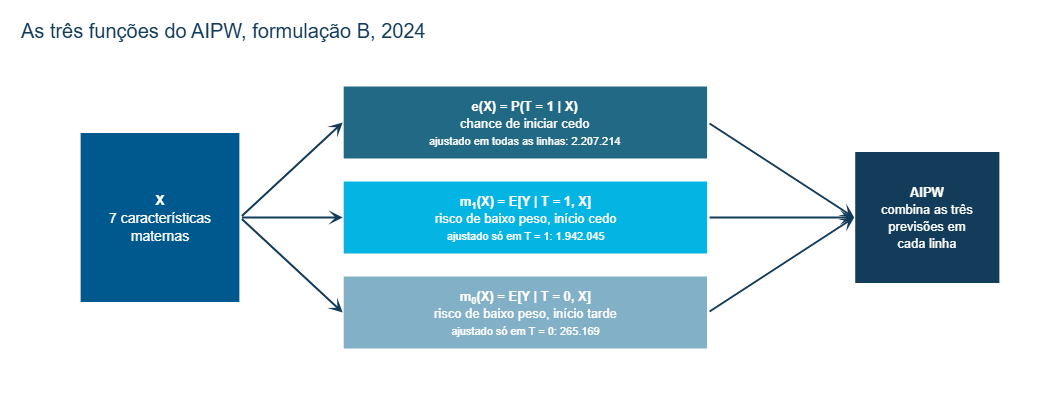

In [3]:
fig = go.Figure(go.Scatter(x=[0, 12.6], y=[0, 6], mode="markers", marker_opacity=0,
                           showlegend=False, hoverinfo="skip"))


def caixa(x0, x1, y0, y1, cor, texto, cor_texto="white", tamanho=13):
    fig.add_shape(type="rect", x0=x0, x1=x1, y0=y0, y1=y1, fillcolor=cor,
                  line=dict(color="white", width=2), layer="below")
    fig.add_annotation(x=(x0 + x1) / 2, y=(y0 + y1) / 2, text=texto, showarrow=False,
                       font=dict(color=cor_texto, size=tamanho))


def seta(x0, y0, x1, y1):
    fig.add_annotation(x=x1, y=y1, ax=x0, ay=y0, xref="x", yref="y", axref="x", ayref="y", text="",
                       showarrow=True, arrowhead=3, arrowsize=1.2, arrowwidth=2,
                       arrowcolor=CORES_IPT["AZUL_ESCURO"])


caixa(0, 2.2, 1.2, 4.8, CORES_IPT["AZUL_PRINCIPAL"], "<b>X</b><br>7 características<br>maternas", tamanho=14)
funcoes = [
    (5.0, CORES_IPT["AZUL_MEDIO"], "<b>e(X) = P(T = 1 | X)</b><br>chance de iniciar cedo",
     f"ajustado em todas as linhas: {num(b24.n)}"),
    (3.0, CORES_IPT["CIANO"], "<b>m<sub>1</sub>(X) = E[Y | T = 1, X]</b><br>risco de baixo peso, início cedo",
     f"ajustado só em T = 1: {num(b24.n_t1)}"),
    (1.0, CORES_IPT["AZUL_CLARO"], "<b>m<sub>0</sub>(X) = E[Y | T = 0, X]</b><br>risco de baixo peso, início tarde",
     f"ajustado só em T = 0: {num(b24.n_t0)}"),
]
for y, cor, texto, ajuste in funcoes:
    caixa(3.6, 8.6, y - 0.78, y + 0.78, cor, f"{texto}<br><span style='font-size:11px'>{ajuste}</span>")
    seta(2.2, 3.0, 3.6, y)
    seta(8.6, y, 10.6, 3.0)
caixa(10.6, 12.6, 1.6, 4.4, CORES_IPT["AZUL_ESCURO"], "<b>AIPW</b><br>combina as três<br>previsões em<br>cada linha")
fig.update_xaxes(visible=False, range=[-0.2, 12.8])
fig.update_yaxes(visible=False, range=[0, 6])
mostrar(fig, "As três funções do AIPW, formulação B, 2024", altura=420, largura=1050)

## 3. O estimador AIPW

Para cada nascido vivo *i*, o AIPW (*Augmented Inverse Probability Weighting*) calcula uma contribuição individual:

$$
\psi_i \;=\; \underbrace{m_1(X_i) - m_0(X_i)}_{\text{previsão do contraste}}
\;+\; \underbrace{\frac{T_i\,\big(Y_i - m_1(X_i)\big)}{e(X_i)}
\;-\; \frac{(1 - T_i)\,\big(Y_i - m_0(X_i)\big)}{1 - e(X_i)}}_{\text{correção pelos resíduos}}
$$

A estimativa do ano é a média das contribuições: $\hat\psi = \frac{1}{n}\sum_i \psi_i$.

Em linguagem natural:

1. **Previsão do contraste.** Os modelos de desfecho preveem o risco de cada gestante nos dois cenários, e a diferença entre eles é um primeiro palpite.
2. **Correção pelos resíduos.** Para quem iniciou cedo, compara-se o desfecho observado com o previsto por m₁(X); para quem iniciou tarde, com o previsto por m₀(X). Essa diferença é o resíduo.
3. **Ponderação pela probabilidade de tratamento.** Cada resíduo é dividido pela chance de a gestante estar no grupo em que está. Observações "raras" para o seu perfil pesam mais, porque representam muitas outras gestantes semelhantes do grupo oposto.

Se os modelos de desfecho acertassem em média, as correções seriam próximas de zero. Quando erram de forma sistemática, a correção ponderada compensa o erro.

## 4. Dupla robustez

O AIPW é chamado de **duplamente robusto**: sob as hipóteses de identificação do notebook 02, a estimativa é consistente se **pelo menos um** dos dois componentes estiver bem especificado, isto é, o modelo de propensão **ou** os modelos de desfecho.

**Protege contra:**

- certas falhas de especificação de **um** dos modelos auxiliares, desde que o outro esteja correto.

**Não protege contra:**

- **confundimento não observado**, como renda, tabagismo, estado nutricional e morbidades, que não estão em X;
- erro de especificação nos **dois** modelos ao mesmo tempo;
- falta de suporte (positividade), avaliada no notebook 03;
- erros de mensuração de T ou de Y e a seleção por nascido vivo.

Ou seja, a dupla robustez não "corrige qualquer erro". Ela reduz a dependência de acertar exatamente a forma de **um** dos modelos auxiliares, mas não cria informação sobre fatores que não estão em X.

## 5. Ajuste cruzado (*cross-fitting*)

Se o mesmo registro fosse usado para ajustar um modelo e para avaliá-lo, o sobreajuste contaminaria a estimativa: o modelo "lembraria" o desfecho daquela gestante. O ajuste cruzado reduz o risco de viés associado a esse sobreajuste.

Em cada ano e formulação:

1. os registros são divididos em **3 partições**;
2. a divisão é **estratificada por 2·T + Y**, que codifica as quatro combinações de grupo e desfecho (0 = tarde sem baixo peso, 1 = tarde com baixo peso, 2 = cedo sem baixo peso, 3 = cedo com baixo peso). Assim, cada partição preserva as mesmas proporções dessas quatro combinações;
3. a semente aleatória é fixa (**20240925**), o que torna a divisão reprodutível;
4. em cada rodada, os modelos são ajustados em duas partições e fazem previsões para a terceira.

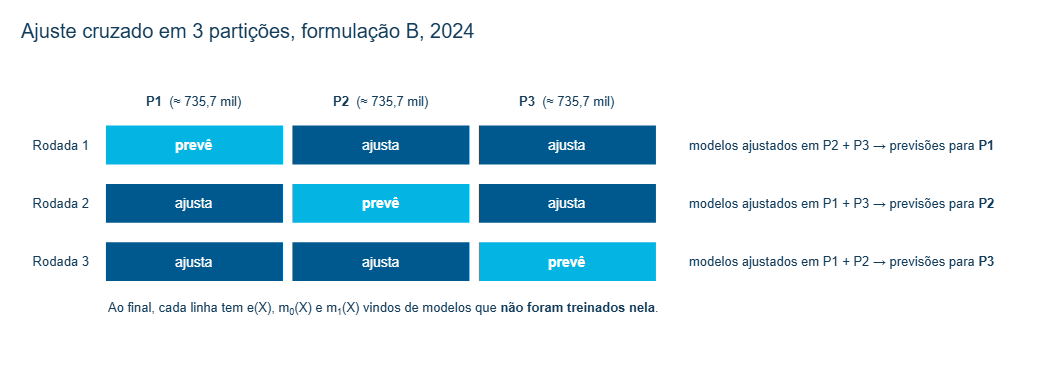

In [4]:
assert manifesto["n_folds"] == 3 and manifesto["seed"] == 20240925 and manifesto["estratificacao"] == "2*T+Y"
por_particao = b24.n / manifesto["n_folds"]

fig = go.Figure(go.Scatter(x=[0, 12], y=[0, 4.4], mode="markers", marker_opacity=0,
                           showlegend=False, hoverinfo="skip"))
COR_TREINO, COR_PREVISAO = CORES_IPT["AZUL_PRINCIPAL"], CORES_IPT["CIANO"]
for rodada in (1, 2, 3):
    y = 4 - rodada
    for particao in (1, 2, 3):
        x0 = (particao - 1) * 2.5
        prever = particao == rodada
        fig.add_shape(type="rect", x0=x0, x1=x0 + 2.4, y0=y - 0.35, y1=y + 0.35,
                      fillcolor=COR_PREVISAO if prever else COR_TREINO, line=dict(color="white", width=2))
        fig.add_annotation(x=x0 + 1.2, y=y, text="<b>prevê</b>" if prever else "ajusta", showarrow=False,
                           font=dict(color="white", size=14))
    outras = " + ".join(f"P{p}" for p in (1, 2, 3) if p != rodada)
    fig.add_annotation(x=7.8, y=y, xanchor="left", showarrow=False, font=dict(size=13),
                       text=f"modelos ajustados em {outras} → previsões para <b>P{rodada}</b>")
for particao in (1, 2, 3):
    fig.add_annotation(x=(particao - 1) * 2.5 + 1.2, y=3.75, showarrow=False, font=dict(size=13),
                       text=f"<b>P{particao}</b>  (≈ {num(por_particao / 1000, 1)} mil)")
fig.add_annotation(x=0, y=0.2, xanchor="left", showarrow=False, font=dict(size=13),
                   text="Ao final, cada linha tem e(X), m<sub>0</sub>(X) e m<sub>1</sub>(X) vindos de modelos que <b>não foram treinados nela</b>.")
fig.update_xaxes(visible=False, range=[-0.2, 12.2])
fig.update_yaxes(tickvals=[3, 2, 1], ticktext=["Rodada 1", "Rodada 2", "Rodada 3"], range=[0, 4.2],
                 showgrid=False, showline=False)
mostrar(fig, "Ajuste cruzado em 3 partições, formulação B, 2024", altura=380, largura=1050, margem_esquerda=90)

- Em cada rodada, os modelos nunca veem a partição que vão prever.
- Depois das três rodadas, **cada nascido vivo recebe previsões de modelos que não foram treinados nele**.
- Os modelos são ajustados do zero em cada formulação, ano e partição. Nenhuma previsão é reaproveitada de outro ano ou de outra formulação.

## 6. Especificações dos modelos auxiliares

Os hiperparâmetros foram fixados antes da estimação, sem busca pelo "melhor" modelo.

In [5]:
especificacoes = pd.DataFrame({
    "Propensão e(X)": ["Regressão logística L2 (C = 1)", "Regressão logística L2 (C = 1)", "Gradient boosting (HGB)"],
    "Desfechos m₀(X) e m₁(X)": ["Regressões logísticas L2, uma por grupo", "HGB, um por grupo",
                                 "HGB (os mesmos de C2)"],
    "Papel": ["referência", "sensibilidade: desfechos flexíveis", "sensibilidade: todos flexíveis"],
}, index=pd.Index(["C1", "C2", "C3"], name="Especificação"))
assert list(manifesto["especificacoes"]) == list(especificacoes.index)
display(especificacoes)

# Qualidade dos modelos auxiliares na formulação B, 2014–2024 (avaliada fora da partição de treino)
qualidade = (nuisance[nuisance.formulacao == "B"]
             .groupby(["alvo", "modelo"])
             .agg(auc_min=("auc", "min"), auc_max=("auc", "max"), calib=("erro_calibracao_maximo", "max")))
assert len(qualidade) == 6
NOMES = {("propensity", "logistica_C1"): "e(X), logística", ("propensity", "hgb_historico"): "e(X), HGB",
         ("outcome_t1", "m1_C1"): "m₁(X), logística", ("outcome_t1", "m1_C2"): "m₁(X), HGB",
         ("outcome_t0", "m0_C1"): "m₀(X), logística", ("outcome_t0", "m0_C2"): "m₀(X), HGB"}
display(pd.DataFrame({
    "AUC (faixa 2014–2024)": [f"{num(qualidade.loc[k, 'auc_min'], 3)} a {num(qualidade.loc[k, 'auc_max'], 3)}"
                              for k in NOMES],
    "Maior erro de calibração": [num(qualidade.loc[k, "calib"], 4) for k in NOMES],
}, index=pd.Index(NOMES.values(), name="Modelo auxiliar, formulação B")))

,Propensão e(X),Desfechos m₀(X) e m₁(X),Papel
Especificação,,,
C1,Regressão logística L2 (C = 1),"Regressões logísticas L2, uma por grupo",referência
C2,Regressão logística L2 (C = 1),"HGB, um por grupo",sensibilidade: desfechos flexíveis
C3,Gradient boosting (HGB),HGB (os mesmos de C2),sensibilidade: todos flexíveis


,AUC (faixa 2014–2024),Maior erro de calibração
"Modelo auxiliar, formulação B",,
"e(X), logística","0,661 a 0,690","0,0056"
"e(X), HGB","0,669 a 0,697","0,0026"
"m₁(X), logística","0,568 a 0,573","0,0028"
"m₁(X), HGB","0,579 a 0,584","0,0019"
"m₀(X), logística","0,580 a 0,587","0,0070"
"m₀(X), HGB","0,588 a 0,596","0,0056"


- A **AUC dos modelos de desfecho é baixa** (0,57 a 0,60): sete características sociodemográficas explicam pouco do peso ao nascer. Isso é esperado e não é um problema em si.
- O que o AIPW exige é que as previsões de risco estejam **bem calibradas**, ou seja, que um risco previsto de 8% corresponda, em média, a 8% observados. O maior erro de calibração por faixa fica abaixo de 0,01 em todos os modelos.
- A comparação dos contrastes entre C1, C2 e C3 está no notebook 05.

## 7. Inferência

Cada estimativa vem acompanhada de um erro-padrão e de um intervalo de confiança de 95%.

- **Leitura principal: erro-padrão agrupado por município de residência.** Nascimentos do mesmo município compartilham serviços de saúde e contexto socioeconômico. Tratá-los como totalmente independentes subestimaria a incerteza. O erro-padrão agrupado soma as contribuições ψᵢ dentro de cada município e mede a variabilidade **entre municípios**.
- São cerca de **5.580 municípios** (*clusters*) por ano. O intervalo usa a distribuição **t com G − 1 graus de liberdade**, em que G é o número de municípios.
- **Referência histórica:** o erro-padrão iid, que trata cada nascido vivo como independente, é mantido apenas para comparação.

In [6]:
b = resultados.query("formulacao == 'B' and trimming == 'sem_trimming'")
assert manifesto["inferencia"]["principal"] == "SE agrupado por CODMUNRES, IC t(G-1)"
assert b.critico_t.round(4).nunique() == 1
print(f"Formulação B, 2014–2024: entre {num(b.n_clusters.min())} e {num(b.n_clusters.max())} municípios por ano; "
      f"valor crítico t(G − 1) = {num(b.critico_t.iloc[0], 4)} em todos os anos.")

Formulação B, 2014–2024: entre 5.580 e 5.587 municípios por ano; valor crítico t(G − 1) = 1,9604 em todos os anos.


Com mais de 5.500 municípios, o valor crítico t(G − 1) é praticamente igual ao 1,96 da distribuição normal. A diferença entre as duas leituras está no **erro-padrão**, e não no valor crítico. O notebook 05 compara os erros-padrão municipal e iid.

## 8. Checagem de reprodução da V1 em 2024

Antes de estimar B e C, o código novo foi testado contra um resultado já conhecido. A **formulação A de 2024**, estimada anteriormente pelo código histórico (V1), foi reestimada do zero pelo código novo, com os mesmos dados, partições e especificações. A comparação cobre 141 verificações.

In [7]:
assert controle["status"] == "CONTROLE_POSITIVO_A2024_APROVADO"
assert controle["n_checks"] == len(controle["checks"]) == 141 and all(controle["checks"].values())
assert not controle["falhas"] and controle["max_abs_delta"] <= controle["tolerancia_absoluta"]


def grupo(nome):
    if nome.startswith("oof_"):
        return "Previsões fora da partição de treino"
    if any(chave in nome for chave in ("estimativa", "se_", "ic95", "n_excluido", "auc")):
        return "Estimativas, erros-padrão, ICs e diagnósticos"
    return "Dados, contagens e partições"


verificacoes = pd.Series([grupo(n) for n in controle["checks"]]).value_counts().rename("Verificações aprovadas")
display(verificacoes.rename_axis("Grupo").to_frame())

v1 = (pd.read_csv(ESTIMATIVAS_V1 / "aipw_anual.csv")
      .query("ano == 2024 and trimming == 'sem_trimming'").set_index("especificacao").estimativa_pp)
v2 = resultados.query("formulacao == 'A' and trimming == 'sem_trimming'").set_index("especificacao").estimativa_pp
reproducao = pd.DataFrame({
    "V1 histórica (p.p.)": v1.map(lambda v: pp(v, 4)),
    "Código novo (p.p.)": v2.map(lambda v: pp(v, 4)),
    "Diferença absoluta": (v2 - v1).abs().map(lambda v: "0" if v == 0 else f"{v:.1e}".replace(".", ",")),
}).rename_axis("A/2024")
assert [round(v, 4) for v in v2] == [-1.3405, -1.2315, -1.2325]
display(reproducao)
print(f"{controle['n_checks']}/{controle['n_checks']} verificações aprovadas | maior diferença: "
      f"{controle['max_abs_delta']:.1e} | tolerância: {controle['tolerancia_absoluta']:.0e}".replace(".", ","))

,Verificações aprovadas
Grupo,
"Estimativas, erros-padrão, ICs e diagnósticos",86
"Dados, contagens e partições",49
Previsões fora da partição de treino,6


,V1 histórica (p.p.),Código novo (p.p.),Diferença absoluta
A/2024,,,
C1,"−1,3405","−1,3405",0
C2,"−1,2315","−1,2315",0
C3,"−1,2325","−1,2325",0


141/141 verificações aprovadas | maior diferença: 2,2e-16 | tolerância: 1e-12


- O código novo reproduziu a V1 de 2024 com diferença máxima de **2,2 × 10⁻¹⁶**, o limite de precisão numérica do computador.
- Os valores reproduzidos foram **C1 = −1,3405 p.p.**, **C2 = −1,2315 p.p.** e **C3 = −1,2325 p.p.**
- Só depois dessa aprovação as formulações B e C foram estimadas.

Esse teste **valida a implementação nova contra a referência histórica**: mostra que o código faz exatamente o que o código anterior fazia. Ele não é uma prova do método, nem garante que as hipóteses de identificação valham.

## 9. Execução para B e C, 2014–2024

A tabela resume o que foi executado na estimação científica original. Este notebook apenas lê os resultados.

In [8]:
ajustes = int((execucao.ajustes_novos + execucao.ajustes_reutilizados).sum())
por_combinacao = 2 * 3 * manifesto["n_folds"]  # 2 propensões + 4 desfechos = 6 modelos, em 3 partições
assert ajustes == len(execucao) * por_combinacao == 414
assert len(resultados) == len(execucao) * len(manifesto["especificacoes"]) * 2

bc = execucao.drop(index="A", level="formulacao")
resumo = pd.DataFrame({"Valor": [
    "B (principal) e C (sensibilidade); A/2024 como checagem de reprodução",
    f"{min(ANOS)}–{max(ANOS)} ({len(ANOS)} anos)",
    f"{len(execucao)} (11 anos × B e C, mais A/2024)",
    "C1, C2 e C3",
    "6: e(X) logística e HGB; m₀(X) e m₁(X) logísticos e HGB",
    f"{manifesto['n_folds']}, estratificadas por 2·T + Y, semente {manifesto['seed']}",
    f"{num(ajustes)} ({len(execucao)} × 6 modelos × 3 partições)",
    f"{num(execucao.segundos_fit_checkpoints.sum() / 3600, 1)} horas",
    f"{num(bc.n.sum())} (B e C somadas)",
    f"{len(resultados)} ({len(execucao)} × 3 especificações × com e sem recorte)",
]}, index=pd.Index(["Formulações", "Anos", "Combinações formulação × ano", "Especificações",
                    "Modelos auxiliares por partição", "Partições", "Ajustes de modelos",
                    "Tempo total de ajuste registrado", "Linhas modeladas", "Estimativas anuais"],
                   name="Execução científica original"))
display(resumo)

,Valor
Execução científica original,
Formulações,B (principal) e C (sensibilidade); A/2024 como...
Anos,2014–2024 (11 anos)
Combinações formulação × ano,"23 (11 anos × B e C, mais A/2024)"
Especificações,"C1, C2 e C3"
Modelos auxiliares por partição,6: e(X) logística e HGB; m₀(X) e m₁(X) logísti...
Partições,"3, estratificadas por 2·T + Y, semente 20240925"
Ajustes de modelos,414 (23 × 6 modelos × 3 partições)
Tempo total de ajuste registrado,"2,0 horas"
Linhas modeladas,54.393.863 (B e C somadas)


## 10. Um exemplo antes dos resultados

Para mostrar o formato de cada resultado, segue a estimativa principal de 2024.

In [9]:
ex = resultados.query("formulacao == 'B' and ano == 2024 and especificacao == 'C1' "
                      "and trimming == 'sem_trimming'").iloc[0]
assert (round(ex.estimativa_pp, 3), round(ex.ic95_cluster_inferior_pp, 3),
        round(ex.ic95_cluster_superior_pp, 3)) == (-1.480, -1.626, -1.335)

display(pd.DataFrame({"B / C1 / 2024": {
    "N": num(ex.n),
    "Contraste AIPW (p.p.)": pp(ex.estimativa_pp),
    "Erro-padrão municipal (p.p.)": num(ex.se_cluster_pp, 3),
    "IC95% municipal (p.p.)": f"{pp(ex.ic95_cluster_inferior_pp)} a {pp(ex.ic95_cluster_superior_pp)}",
    "Municípios": num(ex.n_clusters),
}}))

,B / C1 / 2024
N,2.207.214
Contraste AIPW (p.p.),"−1,480"
Erro-padrão municipal (p.p.),"0,074"
IC95% municipal (p.p.),"−1,626 a −1,335"
Municípios,5.581


**Leitura.** Em 2024, entre nascidos vivos elegíveis da formulação B, o risco padronizado de baixo peso é **1,480 ponto percentual menor** com início do pré-natal no 1º–3º mês do que com início no 4º–6º mês (IC95% municipal: **−1,626 a −1,335 p.p.**). Para comparação, a prevalência de baixo peso na população analítica de 2024 é de 7,89% (notebook 01).

Esse número é um contraste ajustado **sob as hipóteses de identificação** do notebook 02, e não um efeito causal comprovado.

**Próximo notebook:** o conjunto completo de resultados, de 2014 a 2024, nas formulações B e C, nas três especificações e com as análises de sensibilidade.